# Project 3: Insurance Claim Dataset

**Mid-Term 2 - Phân tích theo các tài liệu được cung cấp**

Notebook thực hiện bốn giai đoạn của đề: thu thập và đánh giá, làm sạch, phân tích và trực quan hóa, đánh giá và khuyến nghị. Phần mô hình phân loại áp dụng đúng cách làm trong T14-T15.

**Trước khi Run all trên Colab:** tải `Insurance.csv` lên thư mục làm việc bằng bảng Files ở bên trái; giữ nguyên tên tệp. Mở notebook và chọn Runtime > Run all. CSV phải nằm cùng thư mục làm việc với notebook. Không cần chạy lệnh cài đặt hay gắn Google Drive.

Chỉ dùng lệnh và phương pháp có trong Sources. Không có kiểm định suy luận hoặc p-value trong các bài được gửi; phần giả thuyết dưới đây đối chiếu số liệu trong mẫu theo yêu cầu minh họa của đề, không kết luận ý nghĩa thống kê hay nhân quả.

## Giai đoạn 1. Thu thập và đánh giá dữ liệu ban đầu

Nguồn thực tế: `Insurance.csv` trong `archive.zip` được cung cấp cùng đề `Mid-term-2.pdf`. Đề chỉ định Insurance Claim Dataset tại Kaggle. Không tải thêm dữ liệu hoặc tra cứu thêm phương pháp.

Mục tiêu: mô tả nhãn `insuranceclaim`, tìm khác biệt giữa các nhóm và thực hành phân loại nhãn. Mỗi dòng được gọi là một bản ghi vì không có mã định danh để xác nhận từng khách hàng.

| Cột | Vai trò trong bài |
|---|---|
| age | Tuổi theo tên biến; dùng mô tả và làm đặc trưng |
| sex | Mã 0/1; không tự gán tên giới tính |
| bmi | Chỉ số BMI; dùng mô tả và làm đặc trưng |
| children | Số đếm theo tên biến; chưa có bảng giải thích nghiệp vụ |
| smoker | Mã trạng thái 0/1; trình bày theo mã gốc |
| region | Mã vùng 0-3; không coi là thứ tự lớn/nhỏ |
| charges | Chi phí theo tên biến; đơn vị và thời điểm chưa xác nhận |
| insuranceclaim | Nhãn 0/1 cần mô tả và phân loại |

**Căn cứ lệnh:** T6-T7 (đọc CSV), T15 (head, info, describe), T8-T9 (kiểm tra dữ liệu thiếu và trùng).

In [1]:
# Đọc dữ liệu bằng pandas theo T6-T7; dùng thư viện vẽ theo T12-T15.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình cỡ chữ biểu đồ theo phần cấu hình Matplotlib trong T12.
plt.rcParams['font.size'] = 14

df_raw = pd.read_csv('Insurance.csv')
print('Số dòng và số cột:', df_raw.shape)
print(df_raw.head())
df_raw.info()
print(df_raw.describe().round(2))

Số dòng và số cột: (1338, 8)
   age  sex     bmi  children  smoker  region      charges  insuranceclaim
0   19    0  27.900         0       1       3  16884.92400               1
1   18    1  33.770         1       0       2   1725.55230               1
2   28    1  33.000         3       0       2   4449.46200               0
3   33    1  22.705         0       0       1  21984.47061               0
4   32    1  28.880         0       0       1   3866.85520               1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             1338 non-null   int64  
 1   sex             1338 non-null   int64  
 2   bmi             1338 non-null   float64
 3   children        1338 non-null   int64  
 4   smoker          1338 non-null   int64  
 5   region          1338 non-null   int64  
 6   charges         1338 non-null   float64
 7   insur

In [2]:
# Kiểm tra kiểu dữ liệu, số lượng và tỷ lệ ô thiếu theo T8-T9.
bang_hien_trang = pd.DataFrame({
    'Kieu_du_lieu': df_raw.dtypes,
    'So_o_thieu': df_raw.isna().sum(),
    'Ty_le_thieu_pct': df_raw.isna().sum() / len(df_raw) * 100
})
print(bang_hien_trang)
print('Tổng số ô thiếu:', df_raw.isna().sum().sum())

# Xem các mã thực tế; chưa tự chuyển mã sang tên giới tính hoặc vùng.
for cot in ['sex', 'smoker', 'region', 'insuranceclaim']:
    print('Số lượng theo mã của', cot)
    print(df_raw[cot].value_counts().sort_index())

# Các điều kiện này chỉ kiểm tra dấu của biến, không phải ngưỡng y tế.
print('Số age <= 0:', (df_raw['age'] <= 0).sum())
print('Số bmi <= 0:', (df_raw['bmi'] <= 0).sum())
print('Số children < 0:', (df_raw['children'] < 0).sum())
print('Số charges < 0:', (df_raw['charges'] < 0).sum())
bang_hien_trang.to_csv('Bang_01_Hien_trang.csv', encoding='utf-8-sig')

               Kieu_du_lieu  So_o_thieu  Ty_le_thieu_pct
age                   int64           0              0.0
sex                   int64           0              0.0
bmi                 float64           0              0.0
children              int64           0              0.0
smoker                int64           0              0.0
region                int64           0              0.0
charges             float64           0              0.0
insuranceclaim        int64           0              0.0
Tổng số ô thiếu: 0
Số lượng theo mã của sex
sex
0    662
1    676
Name: count, dtype: int64
Số lượng theo mã của smoker
smoker
0    1064
1     274
Name: count, dtype: int64
Số lượng theo mã của region
region
0    324
1    325
2    364
3    325
Name: count, dtype: int64
Số lượng theo mã của insuranceclaim
insuranceclaim
0    555
1    783
Name: count, dtype: int64
Số age <= 0: 0
Số bmi <= 0: 0
Số children < 0: 0
Số charges < 0: 0


**Nhận xét hiện trạng:** tệp gốc có 1.338 bản ghi và 8 cột; tất cả cột là số, không có ô thiếu. Chỉ có một tệp dữ liệu nên không có bước gộp bảng hay kiểm tra khóa nối. Không điền mean/median và không sửa kiểu dữ liệu khi chưa có lỗi cần sửa. Kiểu `int64` không làm cho `sex` và `region` trở thành biến có thứ tự.

## Giai đoạn 2. Tiền xử lý và làm sạch dữ liệu

**Căn cứ:** T8-T9 hướng dẫn `duplicated()`, `drop_duplicates()`; T12 giới thiệu boxplot; phần Giới thiệu Khoa học dữ liệu có mã `sns.boxplot()`.

In [3]:
# Phát hiện và hiển thị cả hai dòng trong cặp trùng theo T8-T9.
print('Số bản sao cần loại theo quy tắc giữ dòng đầu:', df_raw.duplicated().sum())
print(df_raw[df_raw.duplicated(keep=False)])

# Áp dụng quy tắc khử trùng toàn bộ cột, giữ một bản ghi.
df = df_raw.drop_duplicates().copy()
print('Trước làm sạch:', len(df_raw))
print('Sau làm sạch:', len(df))
print('Tỷ lệ nhãn 1 trước làm sạch (%):', round(df_raw['insuranceclaim'].mean() * 100, 2))
print('Tỷ lệ nhãn 1 sau làm sạch (%):', round(df['insuranceclaim'].mean() * 100, 2))
df.to_csv('Insurance_clean.csv', index=False, encoding='utf-8-sig')

Số bản sao cần loại theo quy tắc giữ dòng đầu: 1
     age  sex    bmi  children  smoker  region    charges  insuranceclaim
195   19    1  30.59         0       0       1  1639.5631               1
581   19    1  30.59         0       0       1  1639.5631               1
Trước làm sạch: 1338
Sau làm sạch: 1337
Tỷ lệ nhãn 1 trước làm sạch (%): 58.52
Tỷ lệ nhãn 1 sau làm sạch (%): 58.49


**Giải trình:** bỏ một bản sao trùng trên cả 8 cột theo cách làm trong T8-T9, còn 1.337 dòng. Đây là quy tắc xử lý của bài; vì không có ID nên chưa thể chứng minh hai dòng trùng chắc chắn là cùng một người. Tệp CSV gốc vẫn đi kèm để đối chiếu.

Không xóa dữ liệu chỉ vì giá trị lớn. Dùng thống kê mô tả và boxplot để nhận diện các điểm cần xem xét. Tài liệu chưa hướng dẫn lệnh tính ngưỡng loại ngoại lệ, nên bài không tự bổ sung một quy tắc cắt dữ liệu.

           bmi   charges
count  1337.00   1337.00
mean     30.66  13279.12
std       6.10  12110.36
min      15.96   1121.87
25%      26.29   4746.34
50%      30.40   9386.16
75%      34.70  16657.72
max      53.13  63770.43


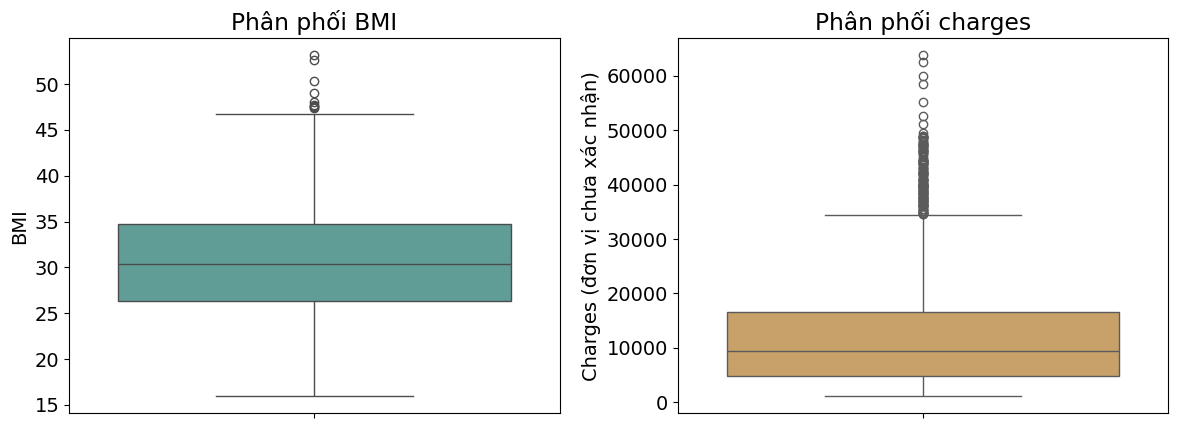

In [4]:
# Xem phân phối và các điểm bất thường bằng boxplot theo ví dụ trong Sources.
print(df[['bmi', 'charges']].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(y='bmi', data=df, color='#56A79E', ax=axes[0])
axes[0].set_title('Phân phối BMI')
axes[0].set_ylabel('BMI')
sns.boxplot(y='charges', data=df, color='#D6A45A', ax=axes[1])
axes[1].set_title('Phân phối charges')
axes[1].set_ylabel('Charges (đơn vị chưa xác nhận)')
plt.tight_layout()
plt.savefig('Hinh_01_Boxplot.png', dpi=180)
plt.show()

**Hình 1:** các điểm tách khỏi phần hộp và râu là tín hiệu cần xem xét, chưa đủ chứng minh lỗi nhập liệu. Chi phí cao có thể là quan sát có thật. Bài giữ nguyên BMI và charges; chỉ bỏ một bản sao ở bước trước. Nhãn trục chi phí không tự gán USD hay VND.

## Giai đoạn 3. Phân tích và trực quan hóa

Mỗi hình đi kèm câu hỏi, bảng số liệu và nhận xét. Dùng tỷ lệ nhãn 1 = tổng nhãn 1 / số bản ghi trong nhóm; vì nhãn chỉ có 0/1, `mean()` chính là tỷ lệ này.

**Căn cứ:** `groupby()` và tính tỷ trọng trong T10-T11, `value_counts()` trong T15; cột, histogram và scatter trong T12-T13; boxplot trong Giới thiệu Khoa học dữ liệu.

**Số liệu Hình 1:** BMI từ 15,96 đến 53,13, trung vị 30,40; charges từ 1.121,87 đến 63.770,43, trung vị 9.386,16. Không có cơ sở xác nhận điểm nào là lỗi, nên giữ nguyên các giá trị này.

Phân tích theo smoker
        So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
smoker                                         
0             1063        533             50.14
1              274        249             90.88
Phân tích theo sex
     So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
sex                                         
0           662        377             56.95
1           675        405             60.00
Phân tích theo region
        So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
region                                         
0              324        192             59.26
1              324        162             50.00
2              364        245             67.31
3              325        183             56.31
Phân tích theo children
          So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
children                                         
0                573        462             80.63
1                324        173             53.40
2                240         94             39.17
3  

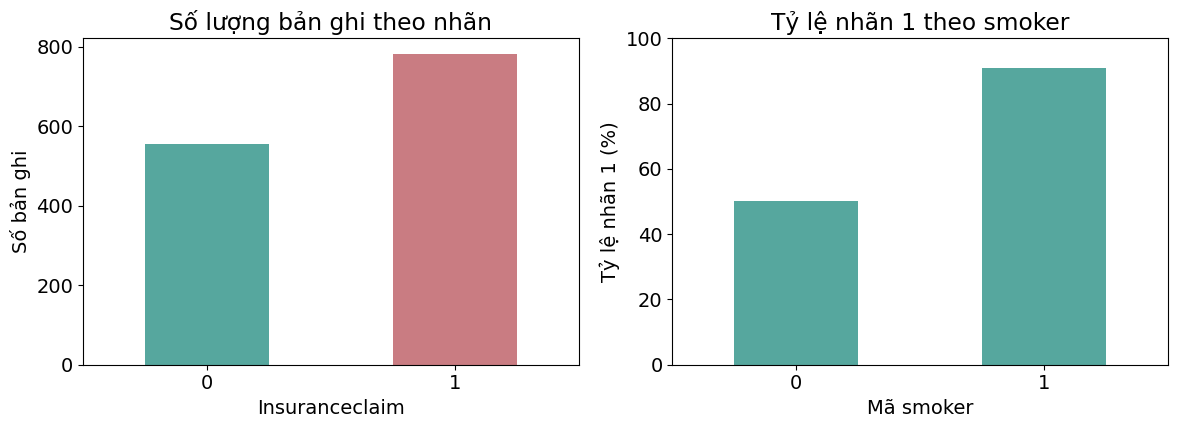

In [5]:
# Bảng so sánh tỷ lệ theo nhóm, dùng groupby và các phép tính cơ bản.
bang_nhom = {}
for cot in ['smoker', 'sex', 'region', 'children']:
    bang = pd.DataFrame({
        'So_ban_ghi': df.groupby(cot)['insuranceclaim'].count(),
        'So_nhan_1': df.groupby(cot)['insuranceclaim'].sum(),
        'Ty_le_nhan_1_pct': df.groupby(cot)['insuranceclaim'].mean() * 100
    })
    bang_nhom[cot] = bang
    print('Phân tích theo', cot)
    print(bang.round(2))
    bang.to_csv('Bang_nhom_' + cot + '.csv', encoding='utf-8-sig')

# Hình 2: quy mô hai nhãn và tỷ lệ nhãn 1 theo smoker.
so_luong_nhan = df['insuranceclaim'].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
so_luong_nhan.plot.bar(ax=axes[0], color=['#56A79E', '#C97C82'], rot=0)
axes[0].set_title('Số lượng bản ghi theo nhãn')
axes[0].set_xlabel('Insuranceclaim')
axes[0].set_ylabel('Số bản ghi')
bang_nhom['smoker']['Ty_le_nhan_1_pct'].plot.bar(ax=axes[1], color='#56A79E', rot=0)
axes[1].set_title('Tỷ lệ nhãn 1 theo smoker')
axes[1].set_xlabel('Mã smoker')
axes[1].set_ylabel('Tỷ lệ nhãn 1 (%)')
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.savefig('Hinh_02_Nhan_va_smoker.png', dpi=180)
plt.show()

**Câu hỏi Hình 2:** hai nhãn có quy mô bằng nhau không; tỷ lệ nhãn 1 của hai mã smoker khác nhau thế nào? Đọc cùng bảng `smoker` để thấy cả số bản ghi và mẫu số của tỷ lệ. Chênh lệch là mối liên hệ trong mẫu, chưa xác định tác động riêng của smoker.

**Số liệu Hình 2:** nhãn 0 có 555 và nhãn 1 có 782 bản ghi; tỷ lệ nhãn 1 là 58,49%. Smoker=0: 533/1.063 = 50,14%; smoker=1: 249/274 = 90,88%; chênh 40,73 điểm phần trăm. Chênh lệch lớn nhưng hai nhóm cũng khác nhau về cỡ mẫu và có thể khác các đặc trưng khác.

Charges trung bình: 13279.12
Charges trung vị: 9386.16
Charges nhỏ nhất: 1121.87
Charges lớn nhất: 63770.43


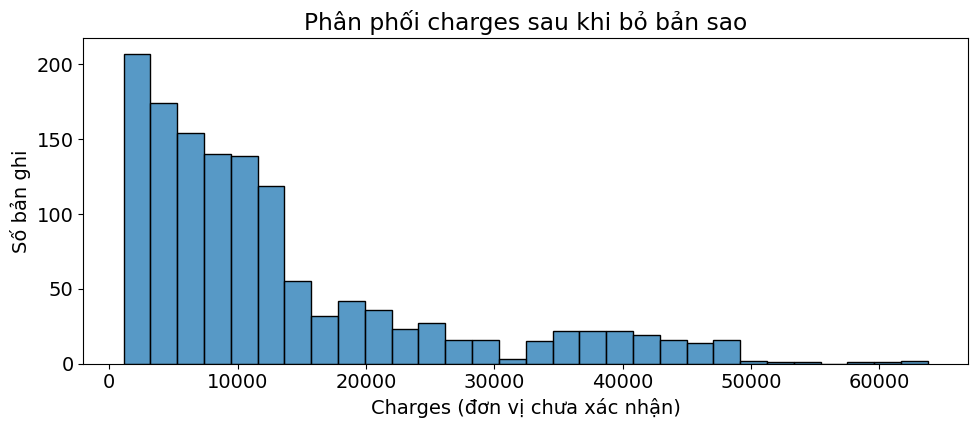

In [6]:
# Hình 3: hình dạng phân phối charges theo histogram trong T12 và T15.
print('Charges trung bình:', round(df['charges'].mean(), 2))
print('Charges trung vị:', round(df['charges'].median(), 2))
print('Charges nhỏ nhất:', round(df['charges'].min(), 2))
print('Charges lớn nhất:', round(df['charges'].max(), 2))
plt.figure(figsize=(10, 4.5))
sns.histplot(df['charges'], bins=30)
plt.title('Phân phối charges sau khi bỏ bản sao')
plt.xlabel('Charges (đơn vị chưa xác nhận)')
plt.ylabel('Số bản ghi')
plt.tight_layout()
plt.savefig('Hinh_03_Phan_phoi_charges.png', dpi=180)
plt.show()

**Câu hỏi Hình 3:** một mức chi phí trung bình có mô tả tốt mọi bản ghi không? So sánh mean với median và quan sát phần kéo dài về phía chi phí cao. Chênh lệch hai chỉ tiêu gợi ý cần báo cáo cả trung bình và trung vị khi trình bày chi phí.

**Số liệu Hình 3:** charges trung bình 13.279,12, trung vị 9.386,16; trung bình cao hơn trung vị 3.892,96. Phân phối kéo dài về phía chi phí cao nên một mức trung bình duy nhất không đại diện tốt cho mọi bản ghi.

           So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
nhom_tuoi                                         
18-29             416        238             57.21
30-44             392        184             46.94
45-64             529        360             68.05
                So_ban_ghi  BMI_trung_binh  BMI_trung_vi  Tuoi_trung_binh
insuranceclaim                                                           
0                      555           27.88         27.26            37.31
1                      782           32.64         32.32            40.58


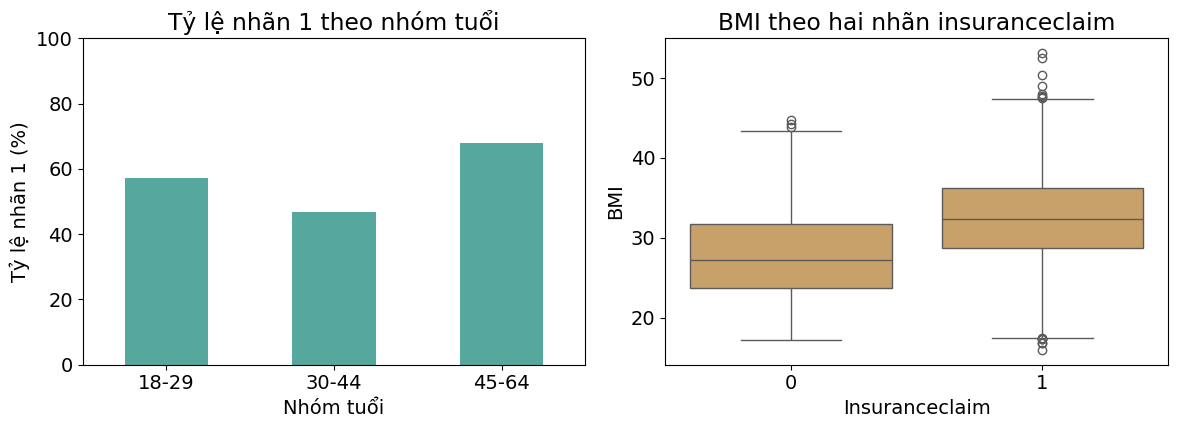

In [7]:
# Tạo nhóm tuổi bằng phép lọc và loc đã dùng trong Sources.
# Các mốc 30 và 45 chỉ để chia nhóm phân tích, không phải ngưỡng rủi ro y tế.
df['nhom_tuoi'] = '18-29'
df.loc[(df['age'] >= 30) & (df['age'] < 45), 'nhom_tuoi'] = '30-44'
df.loc[df['age'] >= 45, 'nhom_tuoi'] = '45-64'
bang_tuoi = pd.DataFrame({
    'So_ban_ghi': df.groupby('nhom_tuoi')['insuranceclaim'].count(),
    'So_nhan_1': df.groupby('nhom_tuoi')['insuranceclaim'].sum(),
    'Ty_le_nhan_1_pct': df.groupby('nhom_tuoi')['insuranceclaim'].mean() * 100
})
print(bang_tuoi.round(2))
bang_tuoi.to_csv('Bang_02_Nhom_tuoi.csv', encoding='utf-8-sig')

# Bảng BMI và tuổi theo nhãn, không dùng thêm ngưỡng phân nhóm BMI.
bang_bmi = pd.DataFrame({
    'So_ban_ghi': df.groupby('insuranceclaim')['bmi'].count(),
    'BMI_trung_binh': df.groupby('insuranceclaim')['bmi'].mean(),
    'BMI_trung_vi': df.groupby('insuranceclaim')['bmi'].median(),
    'Tuoi_trung_binh': df.groupby('insuranceclaim')['age'].mean()
})
print(bang_bmi.round(2))
bang_bmi.to_csv('Bang_03_BMI_theo_nhan.csv', encoding='utf-8-sig')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bang_tuoi['Ty_le_nhan_1_pct'].plot.bar(ax=axes[0], color='#56A79E', rot=0)
axes[0].set_title('Tỷ lệ nhãn 1 theo nhóm tuổi')
axes[0].set_xlabel('Nhóm tuổi')
axes[0].set_ylabel('Tỷ lệ nhãn 1 (%)')
axes[0].set_ylim(0, 100)
sns.boxplot(x='insuranceclaim', y='bmi', data=df, color='#D6A45A', ax=axes[1])
axes[1].set_title('BMI theo hai nhãn insuranceclaim')
axes[1].set_xlabel('Insuranceclaim')
axes[1].set_ylabel('BMI')
plt.tight_layout()
plt.savefig('Hinh_04_Tuoi_va_BMI.png', dpi=180)
plt.show()

**Câu hỏi Hình 4:** nhóm tuổi cao nhất có tỷ lệ nhãn 1 cao hơn nhóm trẻ nhất không; BMI của hai nhãn có khác nhau không? Đọc cả mean, median và độ chồng lấp trên boxplot. Khác biệt trung bình không có nghĩa mọi người có BMI cao đều mang nhãn 1.

**Số liệu Hình 4:** tỷ lệ nhãn 1 ở các nhóm 18-29, 30-44, 45-64 lần lượt là 57,21%, 46,94%, 68,05%. Quan hệ theo ba nhóm không tăng đều. BMI trung bình nhãn 0 là 27,88, nhãn 1 là 32,64, chênh 4,76; BMI trung vị tương ứng 27,27 và 32,32.

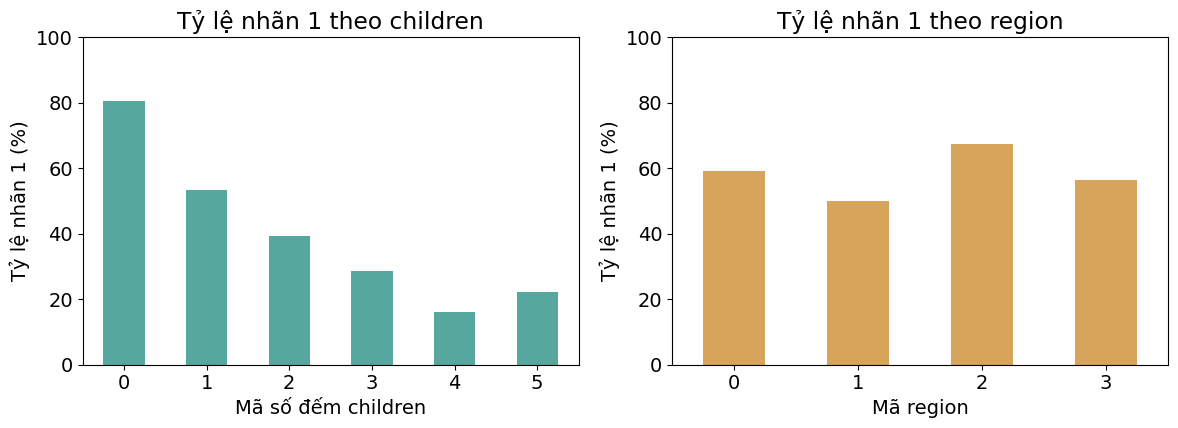

In [8]:
# Hình 5: tránh chỉ so sánh tổng nhãn 1 khi quy mô các nhóm khác nhau.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bang_nhom['children']['Ty_le_nhan_1_pct'].plot.bar(ax=axes[0], color='#56A79E', rot=0)
axes[0].set_title('Tỷ lệ nhãn 1 theo children')
axes[0].set_xlabel('Mã số đếm children')
axes[0].set_ylabel('Tỷ lệ nhãn 1 (%)')
axes[0].set_ylim(0, 100)
bang_nhom['region']['Ty_le_nhan_1_pct'].plot.bar(ax=axes[1], color='#D6A45A', rot=0)
axes[1].set_title('Tỷ lệ nhãn 1 theo region')
axes[1].set_xlabel('Mã region')
axes[1].set_ylabel('Tỷ lệ nhãn 1 (%)')
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.savefig('Hinh_05_Children_va_region.png', dpi=180)
plt.show()

**Câu hỏi Hình 5:** tỷ lệ có biến đổi đều theo children không; các mã vùng khác nhau bao nhiêu? Các nhóm children cao có thể ít bản ghi hơn, nên phải đọc bảng cỡ mẫu đi kèm. Mã region là danh nghĩa, không dùng độ lớn mã để suy ra thứ bậc rủi ro.

**Số liệu Hình 5:** tỷ lệ nhãn 1 theo children=0 đến 5 lần lượt là 80,63%; 53,40%; 39,17%; 28,66%; 16,00%; 22,22%. Nhóm 4 chỉ có 25 và nhóm 5 chỉ có 18 bản ghi; tỷ lệ không giảm liên tục ở bước cuối. Region=2 có tỷ lệ cao nhất 67,31% (245/364); region=1 thấp nhất 50,00% (162/324). Sex=0 là 56,95% và sex=1 là 60,00%, chênh 3,05 điểm phần trăm; chưa xác định nguyên nhân của các chênh lệch.

        So_ban_ghi  Charges_trung_binh  Charges_trung_vi
smoker                                                  
0             1063             8440.66           7345.73
1              274            32050.23          34456.35


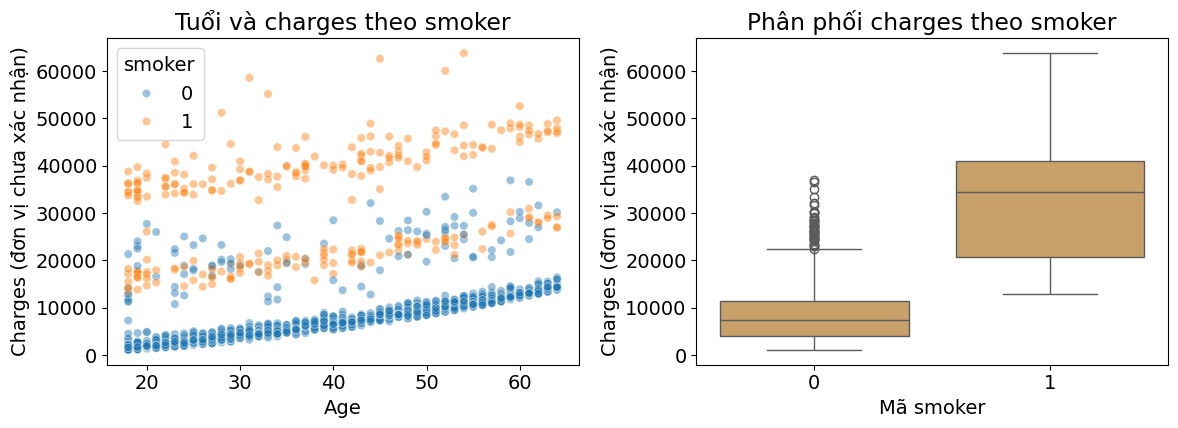

In [9]:
# So sánh charges theo smoker bằng cả mean và median.
bang_charges = pd.DataFrame({
    'So_ban_ghi': df.groupby('smoker')['charges'].count(),
    'Charges_trung_binh': df.groupby('smoker')['charges'].mean(),
    'Charges_trung_vi': df.groupby('smoker')['charges'].median()
})
print(bang_charges.round(2))
bang_charges.to_csv('Bang_04_Charges_theo_smoker.csv', encoding='utf-8-sig')

# Hình 6: scatter cho hai biến số và boxplot so sánh phân phối nhóm.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.45, ax=axes[0])
axes[0].set_title('Tuổi và charges theo smoker')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Charges (đơn vị chưa xác nhận)')
sns.boxplot(x='smoker', y='charges', data=df, color='#D6A45A', ax=axes[1])
axes[1].set_title('Phân phối charges theo smoker')
axes[1].set_xlabel('Mã smoker')
axes[1].set_ylabel('Charges (đơn vị chưa xác nhận)')
plt.tight_layout()
plt.savefig('Hinh_06_Tuoi_charges_smoker.png', dpi=180)
plt.show()

**Câu hỏi Hình 6:** chi phí của hai mã smoker có cùng phân phối không; ở cùng khoảng tuổi có còn các điểm với chi phí rất khác nhau không? Hình phân tán giúp thấy tuổi không giải thích toàn bộ chi phí. Bài không suy ra số tiền tiết kiệm hay mức phí bảo hiểm từ hình này.

### Đối chiếu giả thuyết bằng số liệu trong mẫu

Xét năm nhận định để so sánh với bảng/hình: (1) smoker=1 có tỷ lệ nhãn 1 cao hơn smoker=0; (2) nhóm 45-64 có tỷ lệ cao hơn nhóm 18-29; (3) BMI trung bình của nhãn 1 cao hơn nhãn 0; (4) charges trung bình của smoker=1 cao hơn smoker=0; (5) tỷ lệ nhãn 1 tăng liên tục theo children.

Đây là đối chiếu mô tả, không phải kiểm định thống kê suy luận. Kết quả chỉ ủng hộ hoặc không ủng hộ nhận định trong chính tập mẫu này.

**Số liệu Hình 6:** smoker=0 có charges trung bình 8.440,66 và trung vị 7.345,73; smoker=1 tương ứng 32.050,23 và 34.456,35. Chênh lệch trung bình 23.609,57. Sự khác biệt còn xuất hiện khi so sánh trung vị; chưa chứng minh nguyên nhân và chưa biết đơn vị tiền.

In [10]:
# In số liệu đối chiếu giả thuyết bằng phép trừ và so sánh cơ bản.
print('H1 - Chênh tỷ lệ smoker=1 trừ smoker=0 (điểm phần trăm):',
      round(bang_nhom['smoker'].loc[1, 'Ty_le_nhan_1_pct'] - bang_nhom['smoker'].loc[0, 'Ty_le_nhan_1_pct'], 2))
print('H2 - Chênh tỷ lệ tuổi 45-64 trừ tuổi 18-29 (điểm phần trăm):',
      round(bang_tuoi.loc['45-64', 'Ty_le_nhan_1_pct'] - bang_tuoi.loc['18-29', 'Ty_le_nhan_1_pct'], 2))
print('H3 - Chênh BMI trung bình nhãn 1 trừ nhãn 0:',
      round(bang_bmi.loc[1, 'BMI_trung_binh'] - bang_bmi.loc[0, 'BMI_trung_binh'], 2))
print('H4 - Chênh charges trung bình smoker=1 trừ smoker=0:',
      round(bang_charges.loc[1, 'Charges_trung_binh'] - bang_charges.loc[0, 'Charges_trung_binh'], 2))
print('H5 - Đọc lần lượt các tỷ lệ dưới đây để đối chiếu nhận định tăng liên tục:')
print(bang_nhom['children'].round(2))

H1 - Chênh tỷ lệ smoker=1 trừ smoker=0 (điểm phần trăm): 40.73
H2 - Chênh tỷ lệ tuổi 45-64 trừ tuổi 18-29 (điểm phần trăm): 10.84
H3 - Chênh BMI trung bình nhãn 1 trừ nhãn 0: 4.76
H4 - Chênh charges trung bình smoker=1 trừ smoker=0: 23609.57
H5 - Đọc lần lượt các tỷ lệ dưới đây để đối chiếu nhận định tăng liên tục:
          So_ban_ghi  So_nhan_1  Ty_le_nhan_1_pct
children                                         
0                573        462             80.63
1                324        173             53.40
2                240         94             39.17
3                157         45             28.66
4                 25          4             16.00
5                 18          4             22.22


### Thực hành mô hình phân loại theo T14-T15

Đề tập trung bốn giai đoạn phân tích; mục này bổ sung việc áp dụng các mô hình đã có trong Sources. Dùng sáu đặc trưng `age`, `sex`, `bmi`, `children`, `smoker`, `region` để phân loại `insuranceclaim`. Không dùng `charges` vì chưa rõ biến này có sẵn trước nhãn hay không. Không dùng cột nhóm tuổi vừa tạo.

Tách train/test 80/20 với `random_state=42`, `stratify=y` theo T15. One-hot `sex`, `region` bằng `get_dummies()` theo T8-T9 và đồng bộ cột bằng `align()` theo ví dụ Giới thiệu Khoa học dữ liệu. StandardScaler chỉ học trên train theo T15; chuẩn hóa giúp so sánh các đặc trưng có thang đo khác nhau, không biến phân phối thành chuẩn.

In [11]:
# Chọn đặc trưng, chia train/test trước khi chuẩn hóa theo T15.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = df['insuranceclaim']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# One-hot để mã region không bị hiểu thành số có thứ tự.
X_train_encoded = pd.get_dummies(X_train, columns=['sex', 'region'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['sex', 'region'], drop_first=True)
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded, join='left', axis=1, fill_value=0)

# Chỉ fit trên train; test dùng đúng các tham số học từ train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)
print('Kích thước train:', X_train_encoded.shape)
print('Kích thước test:', X_test_encoded.shape)
print('Các cột sau one-hot:', list(X_train_encoded.columns))
print('Số lượng nhãn trong train:')
print(y_train.value_counts().sort_index())
print('Số lượng nhãn trong test:')
print(y_test.value_counts().sort_index())

Kích thước train: (1069, 8)
Kích thước test: (268, 8)
Các cột sau one-hot: ['age', 'bmi', 'children', 'smoker', 'sex_1', 'region_1', 'region_2', 'region_3']
Số lượng nhãn trong train:
insuranceclaim
0    444
1    625
Name: count, dtype: int64
Số lượng nhãn trong test:
insuranceclaim
0    111
1    157
Name: count, dtype: int64


                 Mo_hinh  Accuracy  Precision  Recall
0    Logistic Regression    0.8619     0.8704  0.8981
1  KNeighbors Classifier    0.8694     0.8765  0.9045
2          Decision Tree    0.8321     0.9828  0.7261
3          Random Forest    0.9403     0.9732  0.9236


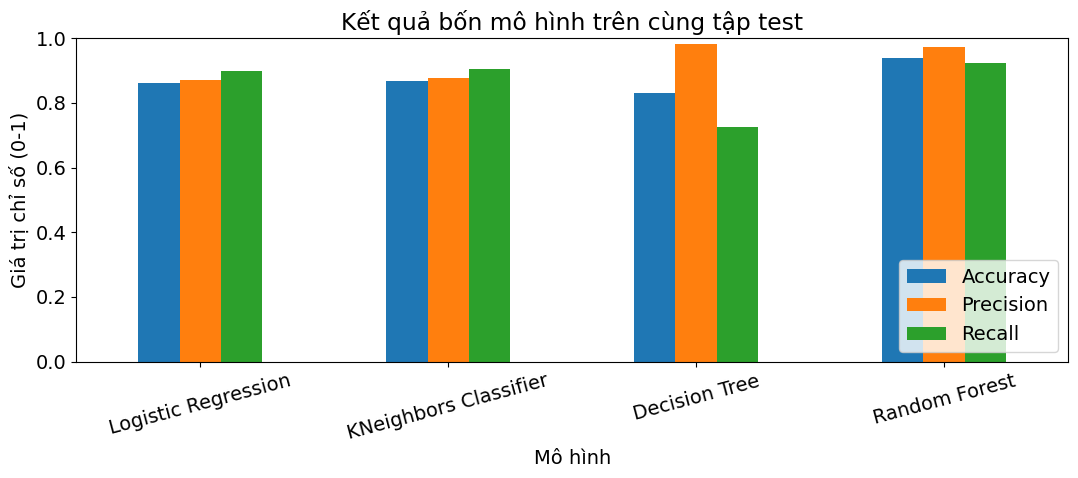

In [12]:
# Khởi tạo đúng bốn mô hình và bộ tham số minh họa phân loại trong T15.
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'KNeighbors Classifier': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=10, random_state=42)
}
ket_qua = []
ma_tran = {}
for ten, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    ket_qua.append({
        'Mo_hinh': ten,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1),
        'Recall': recall_score(y_test, y_pred, pos_label=1)
    })
    ma_tran[ten] = confusion_matrix(y_test, y_pred)

bang_mo_hinh = pd.DataFrame(ket_qua)
print(bang_mo_hinh.round(4))
bang_mo_hinh.to_csv('Bang_05_Ket_qua_mo_hinh.csv', index=False, encoding='utf-8-sig')

# Hình 7: so sánh ba chỉ số có trong phần phân loại T15.
bang_mo_hinh.set_index('Mo_hinh')[['Accuracy', 'Precision', 'Recall']].plot.bar(
    figsize=(11, 5), rot=15)
plt.title('Kết quả bốn mô hình trên cùng tập test')
plt.xlabel('Mô hình')
plt.ylabel('Giá trị chỉ số (0-1)')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('Hinh_07_So_sanh_mo_hinh.png', dpi=180)
plt.show()

**Câu hỏi Hình 7:** mô hình nào có accuracy cao hơn trong lần chia này, và precision/recall của nhãn 1 có đi cùng thứ tự đó không? Accuracy là tỷ lệ dự đoán đúng toàn bộ; precision xét các dự đoán nhãn 1; recall xét các bản ghi thực tế nhãn 1. Báo cáo cả ba để tránh chỉ dựa vào một chỉ số.

Các mô hình dùng cùng tập test để so sánh theo bài thực hành. Không tinh chỉnh tham số sau khi nhìn test. Kết quả chưa phải một đánh giá độc lập bổ sung sau lựa chọn mô hình; không suy ra mô hình tốt nhất cho mọi dữ liệu mới.

**Số liệu Hình 7:** accuracy của Logistic Regression, KNN, Decision Tree và Random Forest lần lượt là 86,19%; 86,94%; 83,21%; 94,03%. Random Forest cao nhất trên lần chia này; Decision Tree có precision nhãn 1 cao (98,28%) nhưng recall thấp hơn (72,61%). Không thể gọi Decision Tree tốt nhất chỉ vì precision cao.

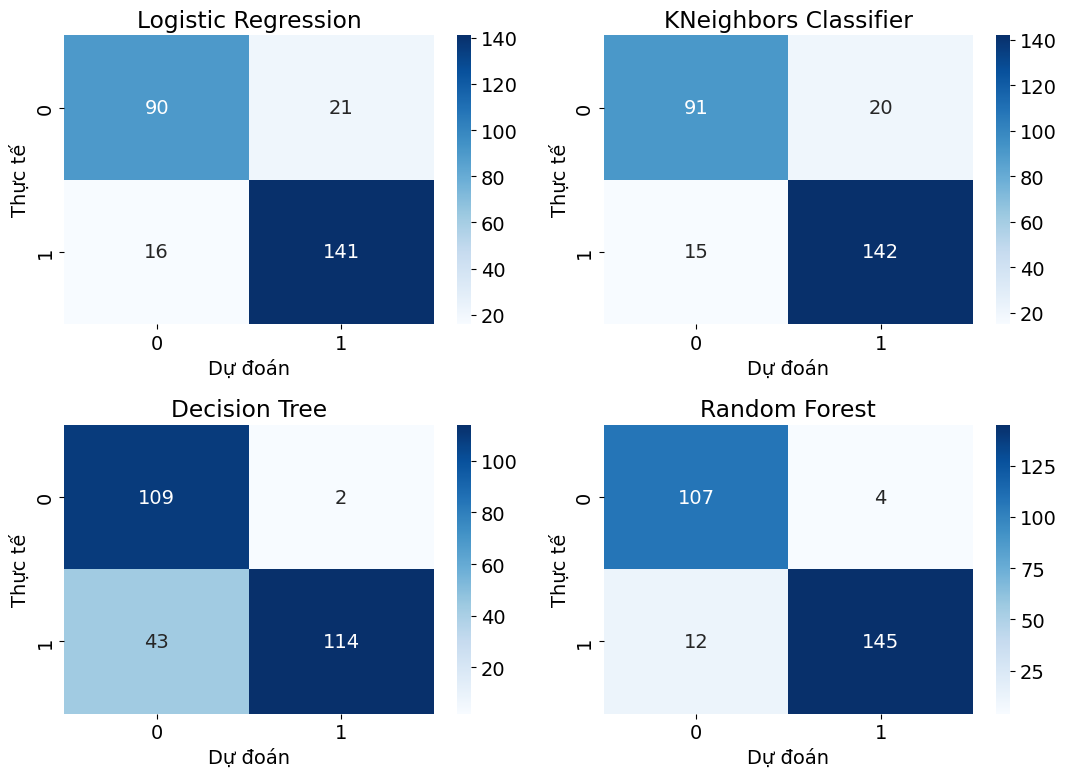

In [13]:
# Hình 8: ma trận nhầm lẫn theo T15, bố trí 2x2 để dễ đọc.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (ten, model) in enumerate(models.items()):
    hang = i // 2
    cot = i % 2
    sns.heatmap(ma_tran[ten], annot=True, fmt='d', cmap='Blues',
                xticklabels=['0', '1'], yticklabels=['0', '1'], ax=axes[hang, cot])
    axes[hang, cot].set_title(ten)
    axes[hang, cot].set_xlabel('Dự đoán')
    axes[hang, cot].set_ylabel('Thực tế')
    pd.DataFrame(ma_tran[ten], index=['Thuc_te_0', 'Thuc_te_1'],
                 columns=['Du_doan_0', 'Du_doan_1']).to_csv(
                     'Ma_tran_' + str(i + 1) + '.csv', encoding='utf-8-sig')
plt.tight_layout()
plt.savefig('Hinh_08_Ma_tran_nham_lan.png', dpi=180)
plt.show()

**Câu hỏi Hình 8:** bao nhiêu bản ghi thực tế nhãn 1 bị đoán thành 0 và ngược lại? Ô hàng 1, cột 0 (nhãn thực tế 1, dự đoán 0) là số trường hợp bỏ sót nhãn 1. Ô hàng 0, cột 1 là số trường hợp dự đoán thừa nhãn 1. Mức độ quan trọng nghiệp vụ của hai sai sót chưa xác định vì thiếu thông tin về chi phí và quy trình xử lý.

## Giai đoạn 4. Đánh giá tác động và khuyến nghị

1. **Chất lượng dữ liệu:** không có ô thiếu; bỏ một bản sao; giữ các giá trị lớn vì chưa có bằng chứng là lỗi. Bổ sung ID và bảng giải thích biến để làm sạch chắc chắn hơn.
2. **Phân tích nhóm:** smoker và BMI có khác biệt rõ trong mẫu. Các nhóm cần đi kèm số bản ghi; không suy từ tỷ lệ quan sát sang nguyên nhân.
3. **Chi phí:** xem cả mean và median, kiểm tra riêng các chi phí cao trước khi lập kế hoạch dự phòng; chưa quy đổi tiền hay ước tính mức phí.
4. **Mô hình:** dùng kết quả để thực hành và xác định bước kiểm tra tiếp theo. Chưa dùng mô hình tự động từ chối, duyệt yêu cầu hoặc định phí.
5. **Giới hạn:** thiếu ID, mốc thời gian, đơn vị tiền, bảng giải mã sex/region, định nghĩa nghiệp vụ của nhãn và cơ chế chọn mẫu. Một lần train/test chưa chứng minh khả năng áp dụng cho quần thể hay thời kỳ khác.
6. **Hướng tiếp theo:** bổ sung thông tin nguồn và một bộ dữ liệu mới để đối chiếu; chỉ mở rộng phương pháp khi đã có tài liệu hướng dẫn phù hợp.

### Bảng đối chiếu tài liệu

| Nội dung | Tài liệu đã cung cấp |
|---|---|
| Bốn giai đoạn, PDF, notebook, GitHub public | Mid-term-2.pdf |
| Đọc và xuất CSV | T6, T7; 6. Nhập và lưu trữ dữ liệu Python |
| Ô thiếu, trùng, one-hot, StandardScaler | T8, T9 |
| Nhóm dữ liệu và tỷ trọng | T10, T11; Giới thiệu về Khoa học dữ liệu |
| Cột, histogram, scatter, bố cục và lưu hình | T12, T13; Data_Viz_KHDL |
| Boxplot | Giới thiệu về Khoa học dữ liệu, ví dụ giá nhà |
| Đồng bộ cột train/test bằng align | Giới thiệu về Khoa học dữ liệu, ví dụ giá nhà |
| Train/test, bốn mô hình, accuracy/precision/recall, confusion matrix | T14, T15 |

**GitHub:** [Project3-Insurance-Claim](https://github.com/duyta848-sys/Project3-Insurance-Claim) - kho công khai lưu toàn bộ báo cáo, notebook, dữ liệu và kết quả của bài.

**Số liệu Hình 8:** số nhãn 1 bị đoán thành 0 lần lượt là 16, 15, 43, 12; số nhãn 0 bị đoán thành 1 lần lượt là 21, 20, 2, 4 theo thứ tự Logistic Regression, KNN, Decision Tree, Random Forest. Random Forest đúng 252/268 bản ghi và sai 16; Decision Tree chỉ có 2 dự đoán thừa nhãn 1 nhưng bỏ sót 43 nhãn 1.